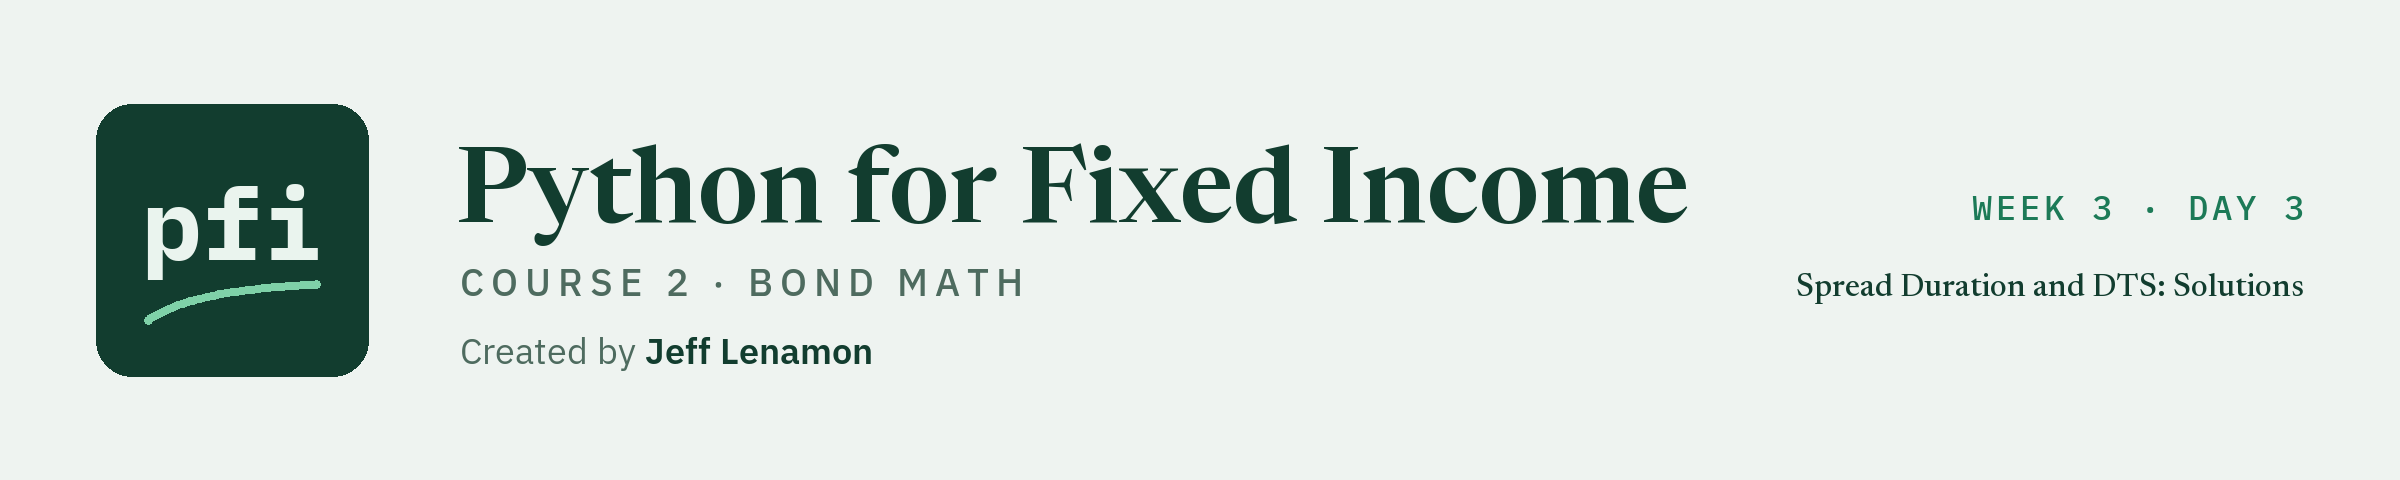

# Spread Duration and DTS: Solutions

Week 3, Day 3. Worked answers to the exercises. Try each one yourself first.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course02_bond_math/week3/day3/13_spread_duration_and_dts_solutions.ipynb)

## Exercises

Run the next cells first: the work folder with the module as this notebook ends it, the libraries and data, `check`, and the twenty bonds.

In [1]:
import os
import sys

# start_day.py sets up each day. On your machine Python finds it in the repo's start_of_day folder;
# in Colab there is no repo, so the cell downloads it from the course's GitHub page.
github = 'https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/course02_bond_math/'
if os.path.exists('../../start_of_day/start_day.py'):
    sys.path.insert(0, '../../start_of_day')
else:
    !wget -q {github}start_of_day/start_day.py
from start_day import start_day

# a new work folder: the Excel files, and the module and its tests as notebook 13 ends.
# To start the day again, restart the kernel and run all cells.
work = start_day(13, after=13)

Work folder pfi_course2_13_k4w7q2xr: 5 data files, the module as notebook 13 left it, 13 commits, tagged week1 and week2


In [2]:
import importlib

import bondmath
import pandas as pd

holdings = pd.read_csv('holdings.csv')
holdings['as_of_date'] = pd.to_datetime(holdings['as_of_date']).dt.date
holdings['maturity'] = pd.to_datetime(holdings['maturity']).dt.date
ratings = pd.read_csv('ratings.csv')
reference = pd.read_csv('bondmath_excel_reference.csv')
excel = reference[reference['group'] == 'holdings'].set_index('case_id')
excel_sd = ((excel['price_down_1bp'] - excel['price_up_1bp']) / (2 * 0.0001)
            / (excel['price'] + excel['accrued']))
bonds = list(zip(holdings['as_of_date'], holdings['maturity'], holdings['coupon'],
                 holdings['yield_pct']))
print(len(bonds), 'bonds,', len(excel_sd), "Excel spread durations")

200 bonds, 200 Excel spread durations


In [3]:
# check() compares your answer with the expected one and prints the result
def check(label, answer, expected):
    if answer is ...:
        print(label + ': not attempted yet')
        return
    if answer is None:
        print(label + ': not yet. Nothing came back: does your function end with return?')
        return
    # isinstance(x, list) is True when x is a list, so a list answer is compared value by value
    if isinstance(expected, list):
        correct = list(answer) == expected  # the same values in the same order
    # getattr(answer, 'ndim', 0) reads answer's ndim, its number of dimensions, as in NumPy
    # Part 1, and gives 0 when answer has none: a single number or a piece of text
    elif getattr(answer, 'ndim', 0) > 0:
        correct = False  # a column or a table where one value is expected
    elif isinstance(expected, float):
        # abs() drops the sign, so this is the size of the gap between the two decimals
        correct = abs(answer - expected) < 0.000001  # decimals: within a tiny tolerance
    else:
        correct = answer == expected
    print(label + ': correct' if correct else label + ': not yet. You have ' + str(answer))

In [4]:
# notebook 12's twenty: every 30th benchmark bond the book does not hold
benchmark = pd.read_csv('benchmark.csv')
not_held = benchmark[~benchmark['cusip'].isin(holdings['cusip'])]
twenty = not_held.iloc[::30].head(20).reset_index(drop=True)
twenty['as_of_date'] = pd.to_datetime(twenty['as_of_date']).dt.date
twenty['maturity'] = pd.to_datetime(twenty['maturity']).dt.date
print(len(twenty), 'bonds')

20 bonds


### Exercise 1

In [5]:
twenty_bonds = list(zip(twenty['as_of_date'], twenty['maturity'], twenty['coupon'],
                        twenty['yield_pct']))
twenty['sd'] = [bondmath.spread_duration(*bond) for bond in twenty_bonds]
gap = (twenty['sd'] - twenty['spread_duration']).abs()
assert (gap <= 0.0005 + 1e-9).all(), "a bond's spread duration differs from the file"
ex1_first = twenty.loc[0, 'sd']
ex1_largest_gap = gap.max()
check('Exercise 1 first spread duration', ex1_first, 6.833695612710124)
check('Exercise 1 largest gap', ex1_largest_gap, 0.0004981682148255118)

Exercise 1 first spread duration: correct
Exercise 1 largest gap: correct


### Exercise 2

In [6]:
twenty['dts_bm'] = bondmath.dts(twenty['sd'], twenty['oas'])
ex2_largest_dts = twenty['dts_bm'].max()
ex2_largest_cusip = twenty.loc[twenty['dts_bm'].idxmax(), 'cusip']
check('Exercise 2 largest DTS', ex2_largest_dts, 1369.6809973159573)
check('Exercise 2 its CUSIP', ex2_largest_cusip, '99055DAB3')

Exercise 2 largest DTS: correct
Exercise 2 its CUSIP: correct


In [7]:
with_bucket = twenty.merge(ratings[['rating', 'bucket', 'score']], on='rating', how='left')
# the best score in each bucket puts the buckets in credit order
by_bucket = (with_bucket.groupby('bucket')
             .agg(bonds=('cusip', 'count'), best_score=('score', 'min'),
                  mean_dts=('dts_bm', 'mean'))
             .sort_values('best_score').drop(columns='best_score'))
by_bucket.round(1)

,bonds,mean_dts
bucket,,
AA,1,332.1
A,6,503.0
BBB,8,1001.1
BB,4,778.8
B,1,950.9


In these twenty bonds the mean DTS is lowest in AA and highest in BBB, with B close behind; the table describes the data and ranks nothing.

### Exercise 3

In [8]:
%%writefile -a bondmath.py


def dts_contribution(weight_pct: float, dts: float) -> float:
    """A bond's contribution to a book's DTS, in years times bp.

    Units: weight_pct in percent of the book's market value, dts in years times bp; the result is
    in years times bp. Convention: weight_pct / 100 x dts. Excel: =weight_cell/100*dts_cell
    """
    return weight_pct / 100 * dts

Appending to bondmath.py


In [9]:
%%writefile -a test_bondmath.py


def test_dts_contribution_known_case():
    # worked by hand: 20 percent of a DTS of 2,000 is 400, and 50 percent of 500 is 250
    assert bondmath.dts_contribution(20.0, 2000.0) == pytest.approx(400.0, abs=1e-12)
    assert bondmath.dts_contribution(50.0, 500.0) == pytest.approx(250.0, abs=1e-12)

Appending to test_bondmath.py


In [10]:
import subprocess
import sys

# python -m pytest -q with this notebook's own Python; -p no:cacheprovider: no cache folder
command = [sys.executable, '-m', 'pytest', '-q', '-p', 'no:cacheprovider', '--tb=no']
# run it in the work folder and keep what it prints
result = subprocess.run(command, cwd=work, capture_output=True, text=True)
print(result.stdout + result.stderr)

......................................                                   [100%]
38 passed in 0.50s



In [11]:
importlib.reload(bondmath)
# the twenty as a small book: each bond's share of their own market value
twenty['book_weight_pct'] = twenty['market_value'] / twenty['market_value'].sum() * 100
ex3_total = bondmath.dts_contribution(twenty['book_weight_pct'], twenty['dts_bm']).sum()
check('Exercise 3 DTS of the twenty', ex3_total, 760.3050140167834)

Exercise 3 DTS of the twenty: correct


38 tests pass, and the twenty's own DTS is 760.3 years x bp.

### Exercise 4: AI check

In [12]:
def assistant_spread_duration(settlement, maturity, coupon_pct, yield_pct, bump_bp=1.0):
    """Spread duration in years: the percent price change for a 100 bp move in the spread."""
    # the bump in percent, to move yield_pct
    bump_pct = bump_bp / 100
    price_down = bondmath.price(settlement, maturity, coupon_pct, yield_pct - bump_pct)
    price_up = bondmath.price(settlement, maturity, coupon_pct, yield_pct + bump_pct)
    full_price = bondmath.dirty_price(settlement, maturity, coupon_pct, yield_pct)
    # the fix: the slope divides by the bump as a decimal, bp over 10000
    return (price_down - price_up) / (2 * bump_bp / 10000) / full_price

In [13]:
for cusip, bond in zip(holdings['cusip'], bonds):
    answer = assistant_spread_duration(*bond)
    expected = excel_sd.loc[cusip]
    assert abs(answer - expected) < 1e-6, f'{cusip}: {answer:.9f}, Excel {expected:.9f}'
ex4_bezane = assistant_spread_duration(*bonds[0])
ex4_dts = bondmath.dts(ex4_bezane, 147)
check('Exercise 4 Bezane spread duration', ex4_bezane, 4.626970799151288)
check('Exercise 4 Bezane DTS', ex4_dts, 680.1647074752394)

Exercise 4 Bezane spread duration: correct
Exercise 4 Bezane DTS: correct


The assistant divided by `2 * bump_bp`, in bp, where the slope needs the bump as a decimal: 10,000 times too small, 0.000463 years for Bezane.
The test from Excel caught it on the first row.